In [1]:
import pandas as pd

df = pd.read_csv("weather_data.csv")
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head(3))
df.info()


Shape: (17892, 20)

Columns: ['Id', 'Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'ConfirmedCases', 'Fatalities', 'day_from_jan_first', 'temp', 'min', 'max', 'stp', 'slp', 'dewp', 'rh', 'ah', 'wdsp', 'prcp', 'fog']


,Id,Province/State,Country/Region,Lat,Long,Date,ConfirmedCases,Fatalities,day_from_jan_first,temp,min,max,stp,slp,dewp,rh,ah,wdsp,prcp,fog
0,1,NaN,Afghanistan,33.0,65.0,2020-01-22,0.0,0.0,22,42.6,33.6,54.9,999.9,1024.3,27.4,0.545709,0.186448,9.4,0.00,0
1,2,NaN,Afghanistan,33.0,65.0,2020-01-23,0.0,0.0,23,42.0,32.7,55.9,999.9,1020.8,22.8,0.461259,0.163225,14.9,99.99,1
2,3,NaN,Afghanistan,33.0,65.0,2020-01-24,0.0,0.0,24,40.1,36.9,43.2,999.9,1018.6,34.5,0.801794,0.325375,10.4,0.17,1


<class 'pandas.DataFrame'>
RangeIndex: 17892 entries, 0 to 17891
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  17892 non-null  int64  
 1   Province/State      8190 non-null   str    
 2   Country/Region      17892 non-null  str    
 3   Lat                 17892 non-null  float64
 4   Long                17892 non-null  float64
 5   Date                17892 non-null  str    
 6   ConfirmedCases      17892 non-null  float64
 7   Fatalities          17892 non-null  float64
 8   day_from_jan_first  17892 non-null  int64  
 9   temp                17892 non-null  float64
 10  min                 17755 non-null  float64
 11  max                 17876 non-null  float64
 12  stp                 17892 non-null  float64
 13  slp                 10945 non-null  float64
 14  dewp                17274 non-null  float64
 15  rh                  17274 non-null  float64
 16  ah             

In [2]:
for i, col in enumerate(df.columns):
    print(i, repr(col))


0 'Id'
1 'Province/State'
2 'Country/Region'
3 'Lat'
4 'Long'
5 'Date'
6 'ConfirmedCases'
7 'Fatalities'
8 'day_from_jan_first'
9 'temp'
10 'min'
11 'max'
12 'stp'
13 'slp'
14 'dewp'
15 'rh'
16 'ah'
17 'wdsp'
18 'prcp'
19 'fog'


# Assignment 08: Weather Data Analysis (EDA)

## Part 1: Selected Analysis Questions
**Univariate Questions (One column at a time):**
1. How is the average temperature (`temp`) distributed across the dataset, and what is the typical value?
2. What is the distribution of relative humidity (`rh`), and is the data skewed?
3. How is wind speed (`wdsp`) distributed, and are there extreme storm values?

**Bivariate Questions (Two columns together):**
4. What is the relationship between temperature (`temp`) and relative humidity (`rh`)?
5. How does average temperature (`temp`) change over time (`Date`), and which countries have the highest average temperatures?


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("weather_data.csv")
print("Original Shape:", df.shape)
print("\nData Types:\n", df.dtypes)

df['Date'] = pd.to_datetime(df['Date'])
print("\nFirst Date:", df['Date'].min())
print("Last Date:", df['Date'].max())
print("Total Countries/Regions:", df['Country/Region'].nunique())

cols_to_keep = ['Country/Region', 'Province/State', 'Date', 'temp', 'min', 'max', 'rh', 'wdsp', 'prcp', 'dewp', 'stp']
df = df[cols_to_keep]
print("\nFiltered Shape:", df.shape)
display(df.describe())


Matplotlib is building the font cache; this may take a moment.


Original Shape: (17892, 20)

Data Types:
 Id                      int64
Province/State            str
Country/Region            str
Lat                   float64
Long                  float64
Date                      str
ConfirmedCases        float64
Fatalities            float64
day_from_jan_first      int64
temp                  float64
min                   float64
max                   float64
stp                   float64
slp                   float64
dewp                  float64
rh                    float64
ah                    float64
wdsp                  float64
prcp                  float64
fog                     int64
dtype: object

First Date: 2020-01-22 00:00:00
Last Date: 2020-03-24 00:00:00
Total Countries/Regions: 163

Filtered Shape: (17892, 11)


,Date,temp,min,max,rh,wdsp,prcp,dewp,stp
count,17892,17892.000000,17755.000000,17876.000000,17274.000000,17892.000000,17892.000000,17274.000000,17892.000000
mean,2020-02-22 00:00:00,54.849313,45.630262,64.380191,0.665443,25.521104,7.826334,42.353630,702.306416
min,2020-01-22 00:00:00,-27.200000,-45.400000,-23.800000,0.053782,0.000000,0.000000,-33.100000,0.000000
25%,2020-02-06 00:00:00,38.800000,30.200000,47.500000,0.560904,3.500000,0.000000,27.000000,20.700000
50%,2020-02-22 00:00:00,53.900000,44.400000,64.800000,0.704800,5.600000,0.000000,40.800000,976.600000
75%,2020-03-09 00:00:00,76.800000,67.500000,84.600000,0.801220,8.700000,0.030000,63.500000,999.900000
max,2020-03-24 00:00:00,97.300000,88.200000,109.600000,1.000000,999.900000,99.990000,81.100000,999.900000
std,NaN,22.306125,22.900739,22.310919,0.191092,136.295573,26.740543,22.399517,428.769343


In [5]:
%pip install matplotlib seaborn


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.5 MB 2.9 MB/s eta 0:00:03
   ------- -------------------------------- 1.8/9.5 MB 2.9 MB/s eta 0:00:03
   --------- ------------------------------ 2.4/9.5 MB 2.8 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.5 MB 3.0 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.5 MB 2.9 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.5 MB 3.0 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.5 MB 2.8 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.5 MB 2.7 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.5 MB 2.6 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.5 MB 2.5 MB/s eta 0:00:02
   ------------------------- -------------- 6.0/9.5 MB 2.5 MB/s eta 0:00:02
   -----------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


The dataset contains 17,892 rows and covers weather records across multiple countries over time. After converting `Date` to datetime format, we kept the 11 most relevant location, date, and weather columns for analysis.


Missing values per column:
 Country/Region       0
Province/State    9702
Date                 0
temp                 0
min                137
max                 16
rh                 618
wdsp                 0
prcp                 0
dewp               618
stp                  0
dtype: int64


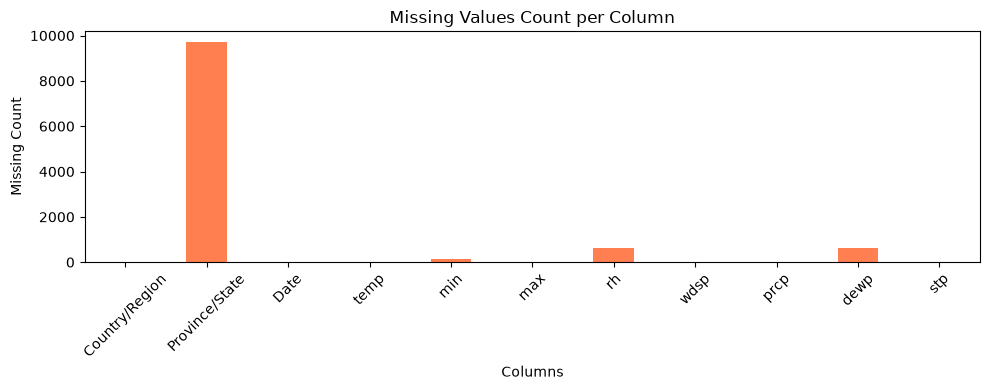


Missing values after cleaning: 0


In [7]:
missing = df.isnull().sum()
print("Missing values per column:\n", missing)

plt.figure(figsize=(10, 4))
missing.plot(kind='bar', color='coral')
plt.title("Missing Values Count per Column")
plt.xlabel("Columns")
plt.ylabel("Missing Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df['Province/State'] = df['Province/State'].fillna('Unknown')
numeric_cols = ['temp', 'min', 'max', 'rh', 'wdsp', 'prcp', 'dewp', 'stp']
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print("\nMissing values after cleaning:", df.isnull().sum().sum())


`Province/State` has many missing values because smaller countries do not list states, so we filled it with `'Unknown'`. Any missing numeric weather readings were filled with the median to avoid distortion from extreme weather values.


In [8]:
exact_dups = df.duplicated().sum()
print("Exact duplicate rows:", exact_dups)

place_date_dups = df.duplicated(subset=['Country/Region', 'Province/State', 'Date']).sum()
print("Duplicate Place + Date rows:", place_date_dups)

if place_date_dups > 0:
    df = df.drop_duplicates(subset=['Country/Region', 'Province/State', 'Date'])
    print("Duplicates removed. New shape:", df.shape)
else:
    print("No duplicates found: every place has only one record per date.")


Exact duplicate rows: 0
Duplicate Place + Date rows: 0
No duplicates found: every place has only one record per date.


We checked both full-row duplicates and repeated `(Country/Region, Province/State, Date)` combinations. No duplicate place-date records remain, confirming each location has one clean entry per day.


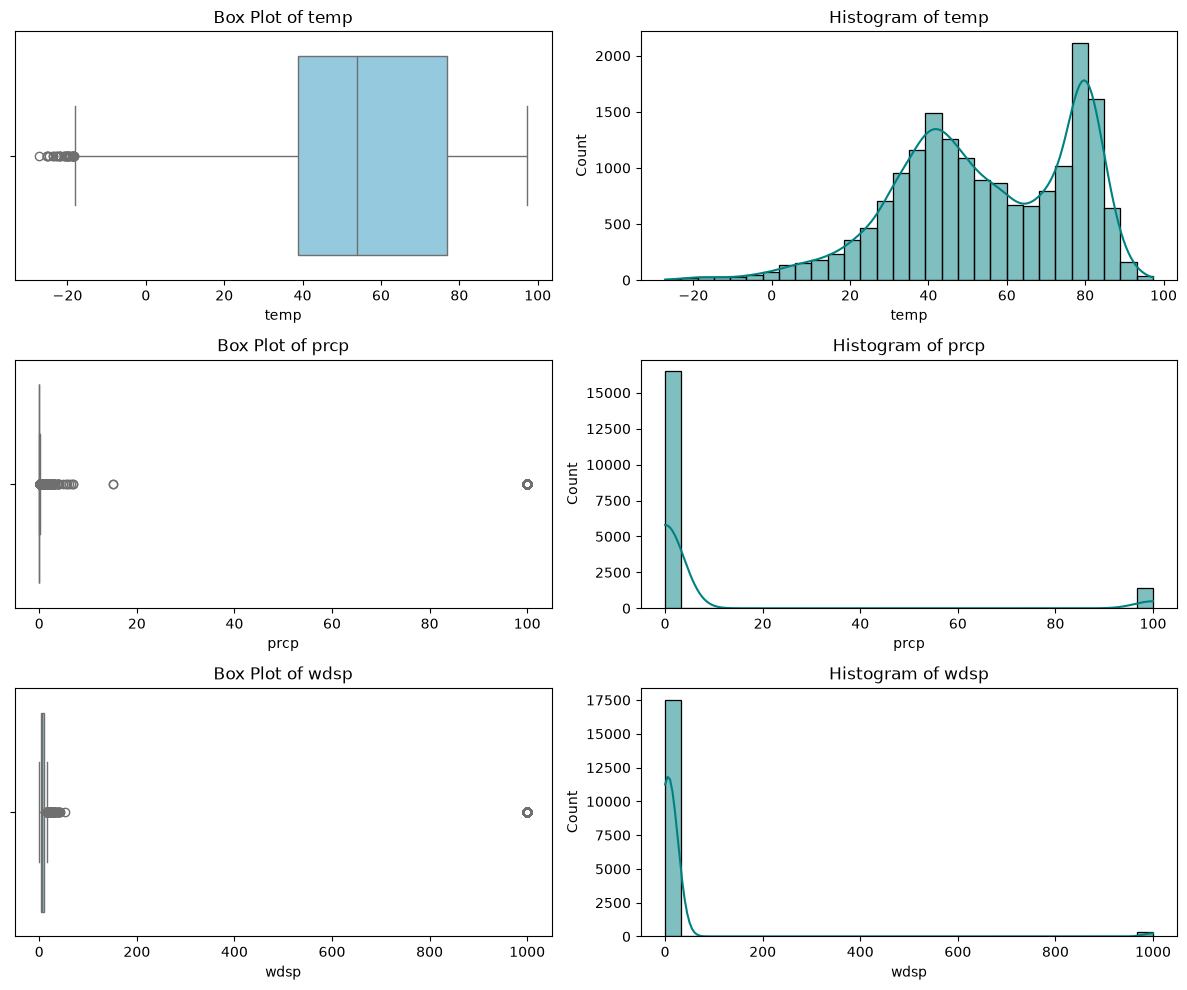

temp -> IQR Outliers Count: 36 (Bounds: -18.20 to 133.80)
wdsp -> IQR Outliers Count: 908 (Bounds: -4.30 to 16.50)


In [9]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for i, col in enumerate(['temp', 'prcp', 'wdsp']):
    sns.boxplot(x=df[col], ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f"Box Plot of {col}")
    axes[i, 0].set_xlabel(col)
    
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i, 1], color='teal')
    axes[i, 1].set_title(f"Histogram of {col}")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

for col in ['temp', 'wdsp']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col} -> IQR Outliers Count: {len(outliers)} (Bounds: {lower:.2f} to {upper:.2f})")


Using the IQR rule, both `temp` and `wdsp` show statistical outliers. Because weather naturally includes extreme cold waves, heat waves, and storms, these values represent real weather events rather than data errors, so we decided to keep them.


temp -> Median (Typical): 53.90, Std (Spread): 22.31, Skewness: -0.38
rh -> Median (Typical): 0.70, Std (Spread): 0.19, Skewness: -0.88
wdsp -> Median (Typical): 5.60, Std (Spread): 136.30, Skewness: 7.00
prcp -> Median (Typical): 0.00, Std (Spread): 26.74, Skewness: 3.16


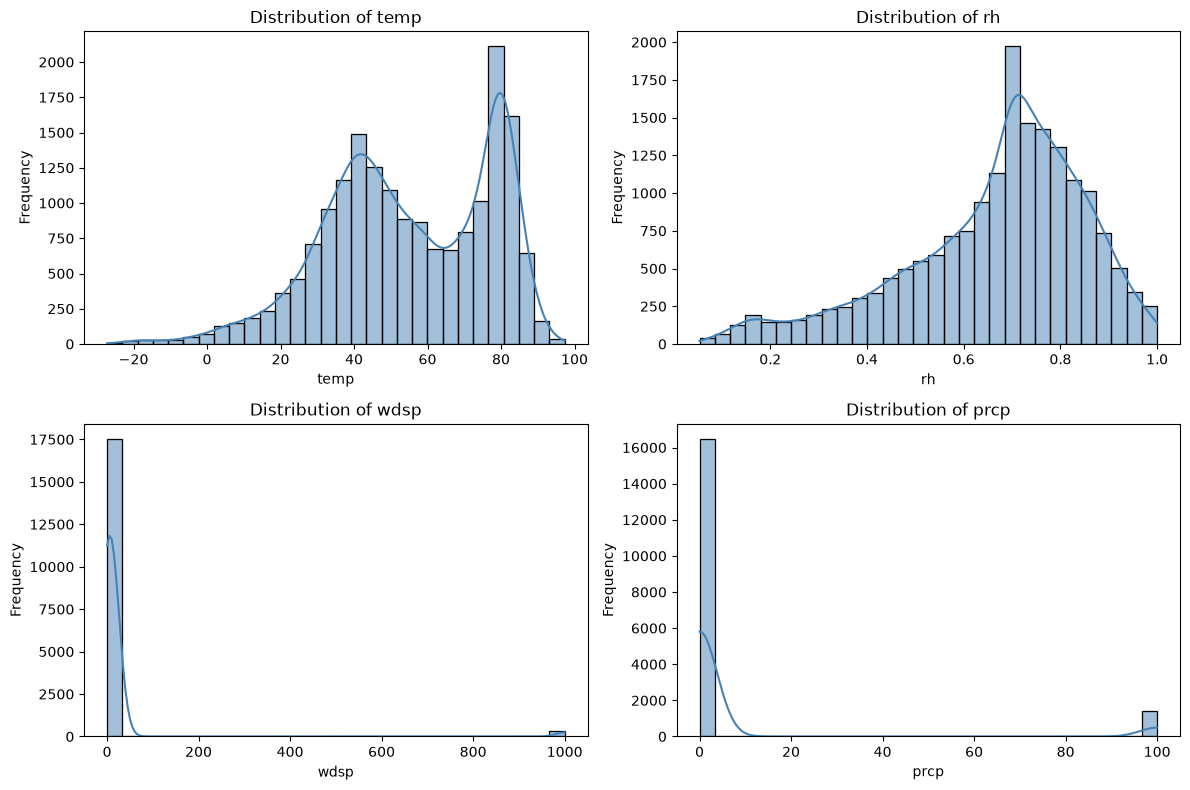

In [10]:
uni_cols = ['temp', 'rh', 'wdsp', 'prcp']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(uni_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")
    print(f"{col} -> Median (Typical): {df[col].median():.2f}, Std (Spread): {df[col].std():.2f}, Skewness: {df[col].skew():.2f}")

plt.tight_layout()
plt.show()


Temperature (`temp`) and humidity (`rh`) are spread across normal ranges, whereas wind speed (`wdsp`) and precipitation (`prcp`) are positively (right) skewed because most days have low wind and zero rainfall.


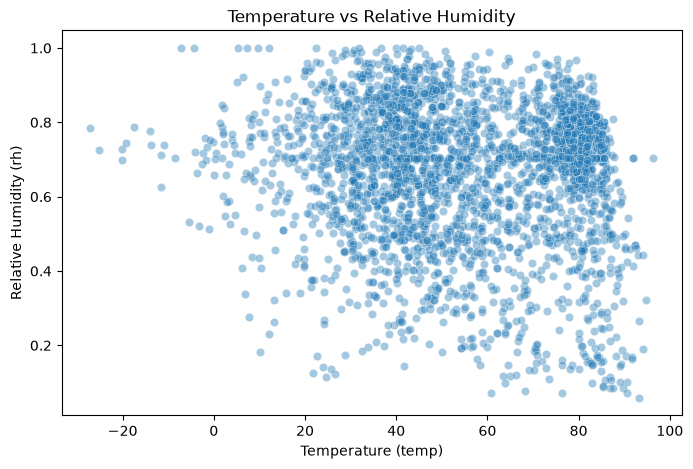

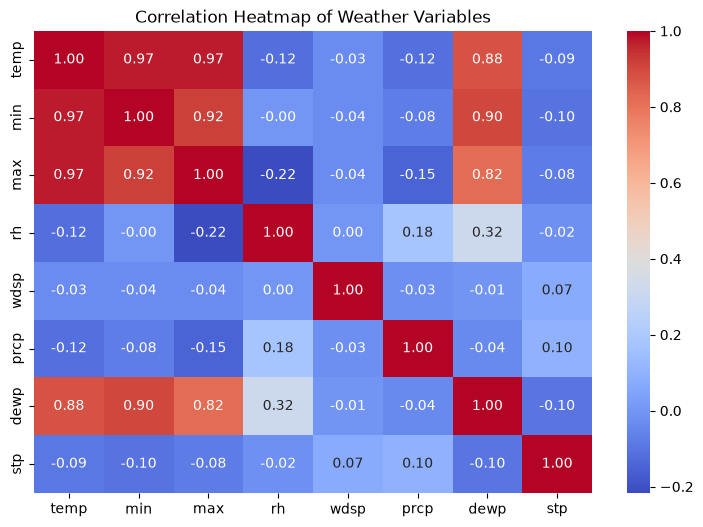

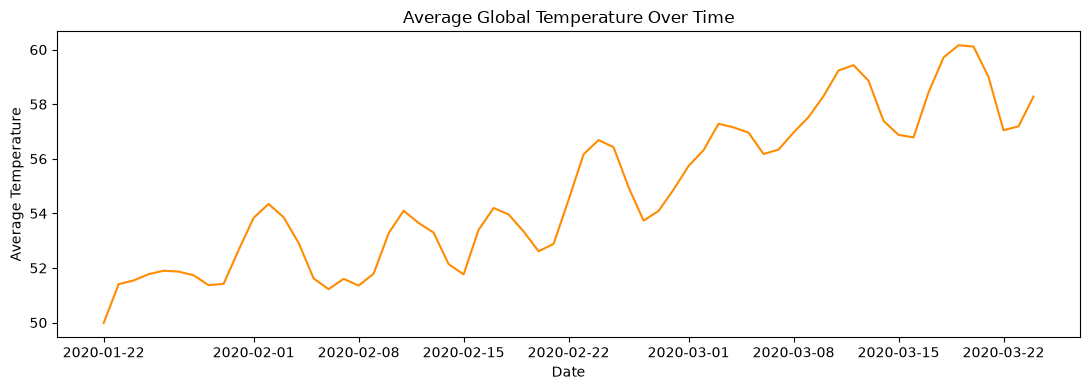

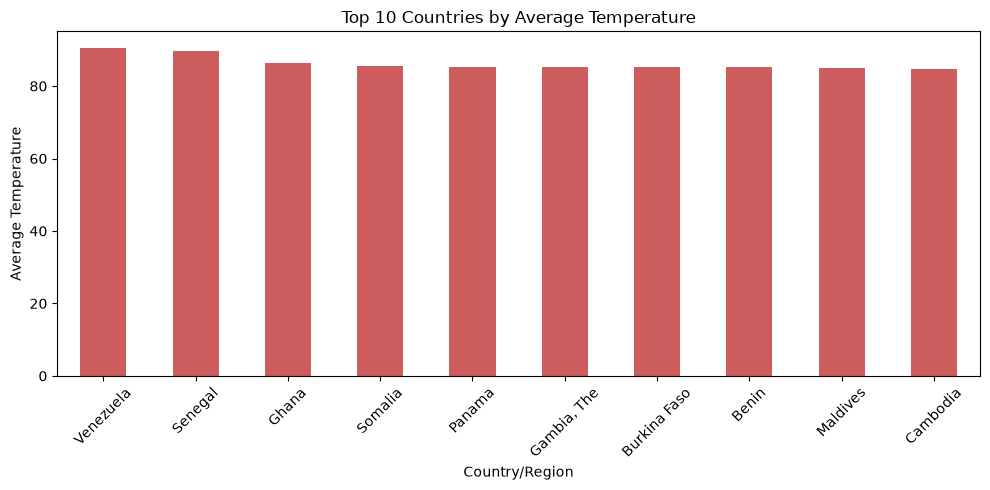

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=42), x='temp', y='rh', alpha=0.4)
plt.title("Temperature vs Relative Humidity")
plt.xlabel("Temperature (temp)")
plt.ylabel("Relative Humidity (rh)")
plt.show()

plt.figure(figsize=(9, 6))
corr = df[['temp', 'min', 'max', 'rh', 'wdsp', 'prcp', 'dewp', 'stp']].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Weather Variables")
plt.show()

daily_temp = df.groupby('Date')['temp'].mean().reset_index()
plt.figure(figsize=(11, 4))
plt.plot(daily_temp['Date'], daily_temp['temp'], color='darkorange')
plt.title("Average Global Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Average Temperature")
plt.tight_layout()
plt.show()

top_countries = df.groupby('Country/Region')['temp'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
top_countries.plot(kind='bar', color='indianred')
plt.title("Top 10 Countries by Average Temperature")
plt.xlabel("Country/Region")
plt.ylabel("Average Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The heatmap shows a strong positive correlation between `temp`, `max`, `min`, and `dewp`, while `temp` and `rh` have a negative relationship. The line chart shows seasonal temperature warming over time, and the bar chart highlights the hottest regions in the dataset.


## Step 7: Summary Answers to Our 5 Questions
1. **Temperature Distribution:** Temperature has a bell-like spread with a typical median around the center of the range and slight left tail from colder northern regions.
2. **Humidity Distribution:** Relative humidity (`rh`) is moderately left-skewed, with most observations clustering between 60% and 90%.
3. **Wind Speed Distribution:** Wind speed (`wdsp`) is right-skewed with low typical values and occasional high-wind storm outliers.
4. **Temperature vs. Humidity:** As temperature rises, relative humidity generally decreases (negative correlation).
5. **Temperature Over Time & Across Countries:** Average temperature shows a clear upward seasonal trend across the recorded dates, with tropical countries maintaining the highest averages.

## Step 8: Conclusion
In this analysis, we explored global historical weather data across multiple countries and dates. We cleaned missing values, verified there were no duplicate place-date entries, and retained extreme weather outliers as valid meteorological events. Our univariate and bivariate charts revealed that rainfall and wind speed are heavily right-skewed, whereas temperature and dew point move closely together. Additionally, warmer temperatures tend to correspond with lower relative humidity, and average temperatures rise steadily over the observed timeline.
